# Variant Well Profiles

In [1]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import polars as pl
from collections import defaultdict
%matplotlib inline

controls = {
    "TC": ["EGFP"],
    "NC": ["RHEB", "MAPK9", "PRKACB", "SLIRP"],
    "PC": ["ALK", "ALK_Arg1275Gln", "PTK2B"],
    # "cPC": ["KRAS", "PTK2B", "GHSR", "ABL1", "BRD4", 
    # "OPRM1", "RB1", "ADA", "WT PMP22", "LYN", "TNF", 
    # "CYP2A6", "CSK", "PAK1", "ALDH2", "CHRM3", "KCNQ2", 
    # "ALK T1151M", "PRKCE", "LPAR1", "PLP1"]
}

ctrl_alleles = [k_v for k_v in controls.values()]
ctrl_alleles_flat = [allele for sublist in ctrl_alleles for allele in sublist]
ctrl_alleles_flat

['EGFP', 'RHEB', 'MAPK9', 'PRKACB', 'SLIRP', 'ALK', 'ALK_Arg1275Gln', 'PTK2B']

## Loading data

### Read in the classifier metrics

In [2]:
# Paths
metrics_dir = "../1_snakemake_pipeline/2025_varchamp_snakemake/snakemake_pipeline/outputs/analyses/{}/profiles_tcdropped_filtered_var_mad_outlier_featselect"
batches = ["2024_01_23_Batch_7", "2024_02_06_Batch_8"]
thresh = 3

metrics_df, metrics_wtvar = pl.DataFrame(), pl.DataFrame()
for batch in batches:
    met_dir = metrics_dir.format(batch)
    metrics_df_batch = pl.read_csv(f"{met_dir}/metrics.csv")
    metrics_wtvar_batch = pl.read_csv(f"{met_dir}/metrics_summary.csv")
    metrics_df = pl.concat([metrics_df, metrics_df_batch])
    metrics_wtvar = pl.concat([metrics_wtvar, metrics_wtvar_batch])


## get the localization metrics
local_wtvar = metrics_wtvar.filter(pl.col("Classifier_type") == "localization")
## get the alleles and their reference genes
local_wtvar = local_wtvar.with_columns(
    pl.when(pl.col("AUROC_mean") > pl.col("AUROC_thresh"))
    .then(1)
    .otherwise(0)
    .alias("mislocalized")
).unique()
misloc_alleles = (
    local_wtvar
    .select("allele_0")
    .to_series()
    .to_list()
)
misloc_wt = (
    local_wtvar
    .with_columns(pl.col("allele_0").str.replace("_.*", "").alias("wt"))
    .select("wt")
    .to_series()
    .unique()
    .to_list()
)
all_alleles = misloc_alleles + misloc_wt

## get individual classifiers pass the training imbalance threshold
ind_class = metrics_df.filter(
    (~pl.col("Metadata_Control"))
    & (pl.col("Training_imbalance") < thresh)
    & (
        (pl.col("Full_Classifier_ID").str.contains("true"))
        & pl.col("allele_0").is_in(all_alleles)
    )
)

misloc_binary = (
    local_wtvar.pivot(
        index=["allele_0", "Allele_set"], ## , "AUROC_mean"
        on="Batch",
        values="mislocalized",
    )
    .with_columns(
        ((pl.col("B7") == 1) & (pl.col("B8") == 1)).alias(
            "mislocalized_both_batches"
        )
    )
    .rename({"B7": "mislocalized_batch7", "B8": "mislocalized_batch8"})
)

sig_misloc_alleles = misloc_binary.filter(pl.col("mislocalized_both_batches"))["allele_0"]

In [3]:
ind_class

AUROC,AUPRC,AUBPRC,Macro_F1,Sensitivity,Specificity,Balanced_Accuracy,Classifier_ID,Full_Classifier_ID,Plate,trainsize_0,testsize_0,well_0,allele_0,trainsize_1,testsize_1,well_1,allele_1,Metadata_Control,train_prob_1,test_prob_1,Training_imbalance,Testing_imbalance
f64,f64,f64,f64,f64,f64,f64,str,str,str,i64,i64,str,str,i64,i64,str,str,bool,f64,f64,f64,f64
0.600219,0.723602,0.587594,0.523385,0.463807,0.640394,0.552101,"""2024_01_22_B7A1R1_P4T4_H09_F09""","""2024_01_22_B7A1R1_P4T4_H09_F09…","""2024_01_22_B7A1R1_P4T4""",1153,203,"""H09""","""TTPA_Asp64Gly""",1070,373,"""F09""","""TTPA""",false,0.481332,0.647569,1.07757,1.837438
0.707959,0.723445,0.748561,0.654405,0.493724,0.823529,0.658627,"""2024_01_17_B7A1R1_P1T3_M02_K02""","""2024_01_17_B7A1R1_P1T3_M02_K02…","""2024_01_17_B7A1R1_P1T3""",702,272,"""M02""","""AMPD2_Glu697Asp""",579,239,"""K02""","""AMPD2""",false,0.451991,0.46771,1.212435,1.138075
0.83739,0.870089,0.85311,0.751481,0.842995,0.657382,0.750188,"""2024_01_17_B7A1R1_P2T4_C08_M06""","""2024_01_17_B7A1R1_P2T4_C08_M06…","""2024_01_17_B7A1R1_P2T4""",670,359,"""C08""","""GSS_Arg283Cys""",1074,414,"""M06""","""GSS""",false,0.615826,0.535576,1.602985,1.153203
0.628188,0.437454,0.613327,0.573296,0.357616,0.785714,0.571665,"""2024_01_19_B7A1R1_P3T4_D20_P18""","""2024_01_19_B7A1R1_P3T4_D20_P18…","""2024_01_19_B7A1R1_P3T4""",1782,616,"""D20""","""SDC3_Val136Ile""",1170,302,"""P18""","""SDC3""",false,0.396341,0.328976,1.523077,2.039735
0.766978,0.66026,0.804085,0.689803,0.522034,0.844302,0.683168,"""2024_01_17_B7A1R1_P1T3_B12_J21""","""2024_01_17_B7A1R1_P1T3_B12_J21…","""2024_01_17_B7A1R1_P1T3""",1494,623,"""B12""","""DES_Pro419Ser""",661,295,"""J21""","""DES""",false,0.306729,0.321351,2.260212,2.111864
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
0.938905,0.876003,0.949498,0.859157,0.774194,0.933333,0.853763,"""2024_01_31_B8A1R2_P1T2_D19_H15""","""2024_01_31_B8A1R2_P1T2_D19_H15…","""2024_01_31_B8A1R2_P1T2""",361,165,"""D19""","""DCX_Arg102Cys""",194,62,"""H15""","""DCX""",false,0.34955,0.273128,1.860825,2.66129
0.988912,0.994274,0.990262,0.951515,0.954955,0.953846,0.954401,"""2024_02_05_B8A1R2_P4T3_K10_C10""","""2024_02_05_B8A1R2_P4T3_K10_C10…","""2024_02_05_B8A1R2_P4T3""",216,65,"""K10""","""TAT_Arg433Trp""",461,111,"""C10""","""TAT""",false,0.680945,0.630682,2.134259,1.707692
0.907733,0.904103,0.926311,0.842757,0.826667,0.86,0.843333,"""2024_02_01_B8A1R2_P2T3_F04_L02""","""2024_02_01_B8A1R2_P2T3_F04_L02…","""2024_02_01_B8A1R2_P2T3""",289,100,"""F04""","""KRT6A_Leu468Pro""",254,75,"""L02""","""KRT6A""",false,0.467772,0.428571,1.137795,1.333333


### Read in cell profiles

In [4]:
# Paths
profile_dir = "../1_snakemake_pipeline/2025_varchamp_snakemake/snakemake_pipeline/outputs/batch_profiles"
pass_qc_prof_dir = f"{profile_dir}/" + "{}/profiles_tcdropped_filtered_var_mad_outlier_featselect.parquet"

# Get meta features
b7_alleles = (
    pl.scan_parquet(
        pass_qc_prof_dir.format(batches[0])
    )
    # .filter(pl.col("Metadata_gene_allele").is_in(all_alleles))
    .with_columns(
        pl.concat_str(
            [
                "Metadata_Plate",
                "Metadata_Well",
                "Metadata_ImageNumber",
                "Metadata_ObjectNumber",
            ],
            separator="_",
        ).alias("Metadata_CellID")
    )
    .select([
        "Metadata_CellID",
        "Metadata_gene_allele",
        "Metadata_Well",
        "Metadata_Plate",
    ])
)

b8_alleles = (
    pl.scan_parquet(
        pass_qc_prof_dir.format(batches[1])
    )
    # .filter(pl.col("Metadata_gene_allele").is_in(all_alleles))
    .with_columns(
        pl.concat_str(
            [
                "Metadata_Plate",
                "Metadata_Well",
                "Metadata_ImageNumber",
                "Metadata_ObjectNumber",
            ],
            separator="_",
        ).alias("Metadata_CellID")
    )
    .select([
        "Metadata_CellID",
        "Metadata_gene_allele",
        "Metadata_Well",
        "Metadata_Plate",
    ])
)

cell_alleles = pl.concat([b7_alleles.collect(), b8_alleles.collect()])

In [5]:
prof_dir = "../1_snakemake_pipeline/2025_varchamp_snakemake/snakemake_pipeline/outputs/batch_profiles/{}/profiles.parquet"

b7_prof = pl.scan_parquet(
    prof_dir.format(batches[0])
).with_columns(
    pl.concat_str(
        [
            "Metadata_Plate",
            "Metadata_Well",
            "Metadata_ImageNumber",
            "Metadata_ObjectNumber",
        ],
        separator="_",
    ).alias("Metadata_CellID")
)
b8_prof = pl.scan_parquet(
    prof_dir.format(batches[1])
).with_columns(
    pl.concat_str(
        [
            "Metadata_Plate",
            "Metadata_Well",
            "Metadata_ImageNumber",
            "Metadata_ObjectNumber",
        ],
        separator="_",
    ).alias("Metadata_CellID")
)

gfp_int = [i for i in b7_prof.collect_schema().names() if "GFP" in i]
gfp_int = ["Metadata_CellID"] + gfp_int

profiles = pl.concat([
    b7_prof.select(gfp_int).collect(),
    b8_prof.select(gfp_int).collect(),
])

# This method of joining ensures that only cells past filters are included in the abundance analysis
profiles = cell_alleles.join(profiles, on="Metadata_CellID", how="left")

### Aggregate to well profiles

In [6]:
well_profiles = (
    profiles.group_by(["Metadata_Plate", "Metadata_Well", "Metadata_gene_allele"])
    .agg(
        pl.col(col).median().alias(col)
        for col in profiles.columns
        if not col.startswith("Metadata_")
    )
    .unique()
    .drop_nulls("Metadata_gene_allele")
)
well_profiles

Metadata_Plate,Metadata_Well,Metadata_gene_allele,Cytoplasm_Correlation_Correlation_AGP_GFP,Cytoplasm_Correlation_Correlation_Brightfield_GFP,Cytoplasm_Correlation_Correlation_Brightfield_H_GFP,Cytoplasm_Correlation_Correlation_Brightfield_L_GFP,Cytoplasm_Correlation_Correlation_DNA_GFP,Cytoplasm_Correlation_Correlation_GFP_Mito,Cytoplasm_Correlation_Costes_AGP_GFP,Cytoplasm_Correlation_Costes_Brightfield_GFP,Cytoplasm_Correlation_Costes_Brightfield_H_GFP,Cytoplasm_Correlation_Costes_Brightfield_L_GFP,Cytoplasm_Correlation_Costes_DNA_GFP,Cytoplasm_Correlation_Costes_GFP_AGP,Cytoplasm_Correlation_Costes_GFP_Brightfield,Cytoplasm_Correlation_Costes_GFP_Brightfield_H,Cytoplasm_Correlation_Costes_GFP_Brightfield_L,Cytoplasm_Correlation_Costes_GFP_DNA,Cytoplasm_Correlation_Costes_GFP_Mito,Cytoplasm_Correlation_Costes_Mito_GFP,Cytoplasm_Correlation_K_AGP_GFP,Cytoplasm_Correlation_K_Brightfield_GFP,Cytoplasm_Correlation_K_Brightfield_H_GFP,Cytoplasm_Correlation_K_Brightfield_L_GFP,Cytoplasm_Correlation_K_DNA_GFP,Cytoplasm_Correlation_K_GFP_AGP,Cytoplasm_Correlation_K_GFP_Brightfield,Cytoplasm_Correlation_K_GFP_Brightfield_H,Cytoplasm_Correlation_K_GFP_Brightfield_L,Cytoplasm_Correlation_K_GFP_DNA,Cytoplasm_Correlation_K_GFP_Mito,Cytoplasm_Correlation_K_Mito_GFP,Cytoplasm_Correlation_Manders_AGP_GFP,Cytoplasm_Correlation_Manders_Brightfield_GFP,Cytoplasm_Correlation_Manders_Brightfield_H_GFP,Cytoplasm_Correlation_Manders_Brightfield_L_GFP,…,Nuclei_Texture_SumAverage_GFP_5_03_256,Nuclei_Texture_SumEntropy_GFP_10_00_256,Nuclei_Texture_SumEntropy_GFP_10_01_256,Nuclei_Texture_SumEntropy_GFP_10_02_256,Nuclei_Texture_SumEntropy_GFP_10_03_256,Nuclei_Texture_SumEntropy_GFP_20_00_256,Nuclei_Texture_SumEntropy_GFP_20_01_256,Nuclei_Texture_SumEntropy_GFP_20_02_256,Nuclei_Texture_SumEntropy_GFP_20_03_256,Nuclei_Texture_SumEntropy_GFP_5_00_256,Nuclei_Texture_SumEntropy_GFP_5_01_256,Nuclei_Texture_SumEntropy_GFP_5_02_256,Nuclei_Texture_SumEntropy_GFP_5_03_256,Nuclei_Texture_SumVariance_GFP_10_00_256,Nuclei_Texture_SumVariance_GFP_10_01_256,Nuclei_Texture_SumVariance_GFP_10_02_256,Nuclei_Texture_SumVariance_GFP_10_03_256,Nuclei_Texture_SumVariance_GFP_20_00_256,Nuclei_Texture_SumVariance_GFP_20_01_256,Nuclei_Texture_SumVariance_GFP_20_02_256,Nuclei_Texture_SumVariance_GFP_20_03_256,Nuclei_Texture_SumVariance_GFP_5_00_256,Nuclei_Texture_SumVariance_GFP_5_01_256,Nuclei_Texture_SumVariance_GFP_5_02_256,Nuclei_Texture_SumVariance_GFP_5_03_256,Nuclei_Texture_Variance_GFP_10_00_256,Nuclei_Texture_Variance_GFP_10_01_256,Nuclei_Texture_Variance_GFP_10_02_256,Nuclei_Texture_Variance_GFP_10_03_256,Nuclei_Texture_Variance_GFP_20_00_256,Nuclei_Texture_Variance_GFP_20_01_256,Nuclei_Texture_Variance_GFP_20_02_256,Nuclei_Texture_Variance_GFP_20_03_256,Nuclei_Texture_Variance_GFP_5_00_256,Nuclei_Texture_Variance_GFP_5_01_256,Nuclei_Texture_Variance_GFP_5_02_256,Nuclei_Texture_Variance_GFP_5_03_256
str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""2024_01_31_B8A1R2_P2T1""","""K14""","""MAPK9""",0.090607,-0.063959,-0.075077,-0.048492,0.188464,0.372463,0.736612,0.000993,0.0,0.001978,0.87742,0.998866,1.0,1.0,1.0,0.187831,1.0,1.0,0.404022,0.096815,0.096662,0.096852,0.844037,2.27289,10.244007,10.259212,10.25356,1.147834,15.382101,0.052514,1.0,1.0,1.0,1.0,…,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""2024_02_02_B8A1R2_P3T1""","""B20""","""SDC3_Asp231Asn""",-0.00011,-0.081426,-0.099466,-0.06959,0.18956,0.596702,0.873633,0.0,0.0,0.0,0.933987,0.999284,0.043266,0.0,0.093113,0.296486,0.998582,0.996911,0.174815,0.091788,0.091691,0.09189,0.936356,5.015657,10.715199,10.731878,10.721807,1.039968,13.66355,0.060277,1.0,1.0,1.0,1.0,

In [7]:
well_profiles_plate_agg = (
    well_profiles.group_by(["Metadata_gene_allele", "Metadata_Well"])
    .agg(
        pl.col(col).median().alias(col)
        for col in well_profiles.columns
        if not col.startswith("Metadata_")
    ).with_columns(
        pl.when(pl.col("Metadata_gene_allele").is_in(ctrl_alleles_flat))
        .then(pl.lit("Control"))
        .otherwise(pl.lit("Allele"))
        .alias("Control_type")
    )
)

In [8]:
well_profiles_plate_agg.filter(pl.col("Metadata_gene_allele").str.contains("ALK")) #.filter(pl.col("Control_type") == "Control")

Metadata_gene_allele,Metadata_Well,Cytoplasm_Correlation_Correlation_AGP_GFP,Cytoplasm_Correlation_Correlation_Brightfield_GFP,Cytoplasm_Correlation_Correlation_Brightfield_H_GFP,Cytoplasm_Correlation_Correlation_Brightfield_L_GFP,Cytoplasm_Correlation_Correlation_DNA_GFP,Cytoplasm_Correlation_Correlation_GFP_Mito,Cytoplasm_Correlation_Costes_AGP_GFP,Cytoplasm_Correlation_Costes_Brightfield_GFP,Cytoplasm_Correlation_Costes_Brightfield_H_GFP,Cytoplasm_Correlation_Costes_Brightfield_L_GFP,Cytoplasm_Correlation_Costes_DNA_GFP,Cytoplasm_Correlation_Costes_GFP_AGP,Cytoplasm_Correlation_Costes_GFP_Brightfield,Cytoplasm_Correlation_Costes_GFP_Brightfield_H,Cytoplasm_Correlation_Costes_GFP_Brightfield_L,Cytoplasm_Correlation_Costes_GFP_DNA,Cytoplasm_Correlation_Costes_GFP_Mito,Cytoplasm_Correlation_Costes_Mito_GFP,Cytoplasm_Correlation_K_AGP_GFP,Cytoplasm_Correlation_K_Brightfield_GFP,Cytoplasm_Correlation_K_Brightfield_H_GFP,Cytoplasm_Correlation_K_Brightfield_L_GFP,Cytoplasm_Correlation_K_DNA_GFP,Cytoplasm_Correlation_K_GFP_AGP,Cytoplasm_Correlation_K_GFP_Brightfield,Cytoplasm_Correlation_K_GFP_Brightfield_H,Cytoplasm_Correlation_K_GFP_Brightfield_L,Cytoplasm_Correlation_K_GFP_DNA,Cytoplasm_Correlation_K_GFP_Mito,Cytoplasm_Correlation_K_Mito_GFP,Cytoplasm_Correlation_Manders_AGP_GFP,Cytoplasm_Correlation_Manders_Brightfield_GFP,Cytoplasm_Correlation_Manders_Brightfield_H_GFP,Cytoplasm_Correlation_Manders_Brightfield_L_GFP,Cytoplasm_Correlation_Manders_DNA_GFP,…,Nuclei_Texture_SumEntropy_GFP_10_00_256,Nuclei_Texture_SumEntropy_GFP_10_01_256,Nuclei_Texture_SumEntropy_GFP_10_02_256,Nuclei_Texture_SumEntropy_GFP_10_03_256,Nuclei_Texture_SumEntropy_GFP_20_00_256,Nuclei_Texture_SumEntropy_GFP_20_01_256,Nuclei_Texture_SumEntropy_GFP_20_02_256,Nuclei_Texture_SumEntropy_GFP_20_03_256,Nuclei_Texture_SumEntropy_GFP_5_00_256,Nuclei_Texture_SumEntropy_GFP_5_01_256,Nuclei_Texture_SumEntropy_GFP_5_02_256,Nuclei_Texture_SumEntropy_GFP_5_03_256,Nuclei_Texture_SumVariance_GFP_10_00_256,Nuclei_Texture_SumVariance_GFP_10_01_256,Nuclei_Texture_SumVariance_GFP_10_02_256,Nuclei_Texture_SumVariance_GFP_10_03_256,Nuclei_Texture_SumVariance_GFP_20_00_256,Nuclei_Texture_SumVariance_GFP_20_01_256,Nuclei_Texture_SumVariance_GFP_20_02_256,Nuclei_Texture_SumVariance_GFP_20_03_256,Nuclei_Texture_SumVariance_GFP_5_00_256,Nuclei_Texture_SumVariance_GFP_5_01_256,Nuclei_Texture_SumVariance_GFP_5_02_256,Nuclei_Texture_SumVariance_GFP_5_03_256,Nuclei_Texture_Variance_GFP_10_00_256,Nuclei_Texture_Variance_GFP_10_01_256,Nuclei_Texture_Variance_GFP_10_02_256,Nuclei_Texture_Variance_GFP_10_03_256,Nuclei_Texture_Variance_GFP_20_00_256,Nuclei_Texture_Variance_GFP_20_01_256,Nuclei_Texture_Variance_GFP_20_02_256,Nuclei_Texture_Variance_GFP_20_03_256,Nuclei_Texture_Variance_GFP_5_00_256,Nuclei_Texture_Variance_GFP_5_01_256,Nuclei_Texture_Variance_GFP_5_02_256,Nuclei_Texture_Variance_GFP_5_03_256,Control_type
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""ALK_Arg1275Gln""","""I10""",0.360004,-0.120353,-0.15107,-0.099037,0.25123,0.741905,0.955328,0.0,0.0,0.0,0.9845,1.0,0.0,0.0,0.0,0.642339,1.0,0.99854,0.412041,0.105112,0.105155,0.105087,0.837899,2.217891,8.998069,8.987666,9.013741,1.111094,19.516404,0.043864,1.0,1.0,1.0,1.0,1.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""Control"""
"""ALK_Arg1275Gln""","""I09""",0.277235,-0.133806,-0.166434,-0.106971,0.262898,0.747212,0.964972,0.0,0.0,0.0,0.979236,1.0,0.0,0.0,0.0,0.678212,1.0,0.999121,0.338102,0.12408,0.123983,0.124078,0.794153,2.65026,7.730266,7.729184,7.733918,1.086095,16.824466,0.049328,1.0,1.0,1.0,1.0,1.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,

## Co-localization patterns

In [9]:
## Select colocalization metrics between meaningful channels
## Select columns that contain "Correlation" but not "Brightfield", brightfield doesn't provide useful information here
colocal_cols = [col for col in well_profiles.columns if "Correlation" in col and "Brightfield" not in col]
colocal_col_cat = set(["_".join(col.split('_')[1:3]) for col in colocal_cols])
print(colocal_col_cat)

colocal_col_dict = defaultdict(list)
for col in colocal_cols:
    colocal_col_dict["_".join(col.split('_')[1:3])].append(col)
# colocal_col_dict

{'Correlation_Correlation', 'Texture_Correlation', 'Correlation_Overlap', 'Correlation_Costes', 'Correlation_Manders', 'Correlation_RWC', 'Correlation_K'}


## WT gene well profiles

In [16]:
well_profiles_wt = well_profiles.filter(
    ~pl.col("Metadata_gene_allele").str.contains("_")
).sort(
    pl.col(["Metadata_gene_allele","Metadata_Plate"])
)
well_profiles_wt

Metadata_Plate,Metadata_Well,Metadata_gene_allele,Cytoplasm_Correlation_Correlation_AGP_GFP,Cytoplasm_Correlation_Correlation_Brightfield_GFP,Cytoplasm_Correlation_Correlation_Brightfield_H_GFP,Cytoplasm_Correlation_Correlation_Brightfield_L_GFP,Cytoplasm_Correlation_Correlation_DNA_GFP,Cytoplasm_Correlation_Correlation_GFP_Mito,Cytoplasm_Correlation_Costes_AGP_GFP,Cytoplasm_Correlation_Costes_Brightfield_GFP,Cytoplasm_Correlation_Costes_Brightfield_H_GFP,Cytoplasm_Correlation_Costes_Brightfield_L_GFP,Cytoplasm_Correlation_Costes_DNA_GFP,Cytoplasm_Correlation_Costes_GFP_AGP,Cytoplasm_Correlation_Costes_GFP_Brightfield,Cytoplasm_Correlation_Costes_GFP_Brightfield_H,Cytoplasm_Correlation_Costes_GFP_Brightfield_L,Cytoplasm_Correlation_Costes_GFP_DNA,Cytoplasm_Correlation_Costes_GFP_Mito,Cytoplasm_Correlation_Costes_Mito_GFP,Cytoplasm_Correlation_K_AGP_GFP,Cytoplasm_Correlation_K_Brightfield_GFP,Cytoplasm_Correlation_K_Brightfield_H_GFP,Cytoplasm_Correlation_K_Brightfield_L_GFP,Cytoplasm_Correlation_K_DNA_GFP,Cytoplasm_Correlation_K_GFP_AGP,Cytoplasm_Correlation_K_GFP_Brightfield,Cytoplasm_Correlation_K_GFP_Brightfield_H,Cytoplasm_Correlation_K_GFP_Brightfield_L,Cytoplasm_Correlation_K_GFP_DNA,Cytoplasm_Correlation_K_GFP_Mito,Cytoplasm_Correlation_K_Mito_GFP,Cytoplasm_Correlation_Manders_AGP_GFP,Cytoplasm_Correlation_Manders_Brightfield_GFP,Cytoplasm_Correlation_Manders_Brightfield_H_GFP,Cytoplasm_Correlation_Manders_Brightfield_L_GFP,…,Nuclei_Texture_SumAverage_GFP_5_03_256,Nuclei_Texture_SumEntropy_GFP_10_00_256,Nuclei_Texture_SumEntropy_GFP_10_01_256,Nuclei_Texture_SumEntropy_GFP_10_02_256,Nuclei_Texture_SumEntropy_GFP_10_03_256,Nuclei_Texture_SumEntropy_GFP_20_00_256,Nuclei_Texture_SumEntropy_GFP_20_01_256,Nuclei_Texture_SumEntropy_GFP_20_02_256,Nuclei_Texture_SumEntropy_GFP_20_03_256,Nuclei_Texture_SumEntropy_GFP_5_00_256,Nuclei_Texture_SumEntropy_GFP_5_01_256,Nuclei_Texture_SumEntropy_GFP_5_02_256,Nuclei_Texture_SumEntropy_GFP_5_03_256,Nuclei_Texture_SumVariance_GFP_10_00_256,Nuclei_Texture_SumVariance_GFP_10_01_256,Nuclei_Texture_SumVariance_GFP_10_02_256,Nuclei_Texture_SumVariance_GFP_10_03_256,Nuclei_Texture_SumVariance_GFP_20_00_256,Nuclei_Texture_SumVariance_GFP_20_01_256,Nuclei_Texture_SumVariance_GFP_20_02_256,Nuclei_Texture_SumVariance_GFP_20_03_256,Nuclei_Texture_SumVariance_GFP_5_00_256,Nuclei_Texture_SumVariance_GFP_5_01_256,Nuclei_Texture_SumVariance_GFP_5_02_256,Nuclei_Texture_SumVariance_GFP_5_03_256,Nuclei_Texture_Variance_GFP_10_00_256,Nuclei_Texture_Variance_GFP_10_01_256,Nuclei_Texture_Variance_GFP_10_02_256,Nuclei_Texture_Variance_GFP_10_03_256,Nuclei_Texture_Variance_GFP_20_00_256,Nuclei_Texture_Variance_GFP_20_01_256,Nuclei_Texture_Variance_GFP_20_02_256,Nuclei_Texture_Variance_GFP_20_03_256,Nuclei_Texture_Variance_GFP_5_00_256,Nuclei_Texture_Variance_GFP_5_01_256,Nuclei_Texture_Variance_GFP_5_02_256,Nuclei_Texture_Variance_GFP_5_03_256
str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""2024_01_19_B7A1R1_P4T1""","""B02""","""ABL1""",0.186721,-0.121538,-0.137762,-0.10464,0.252327,0.663904,0.911561,0.0,0.0,0.0,0.939093,0.995998,1.0,1.0,1.0,0.452679,1.0,1.0,0.114418,0.099161,0.099117,0.099309,0.862887,7.716139,9.833138,9.844804,9.841791,1.070015,16.476594,0.050019,1.0,1.0,1.0,1.0,…,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""2024_01_22_B7A1R1_P4T3""","""B02""","""ABL1""",0.254225,-0.125343,-0.135044,-0.101797,0.255832,0.734529,0.930855,0.0,0.0,0.0,0.933677,0.999558,1.0,0.032032,0.00288,0.160594,1.0,1.0,0.2002,0.103922,0.103644,0.104143,0.888582,4.474486,9.408532,9.418111,9.416058,1.050195,18.271166,0.045561,1.0,1.0,1.0,1.0,…,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,

### Co-localization patterns

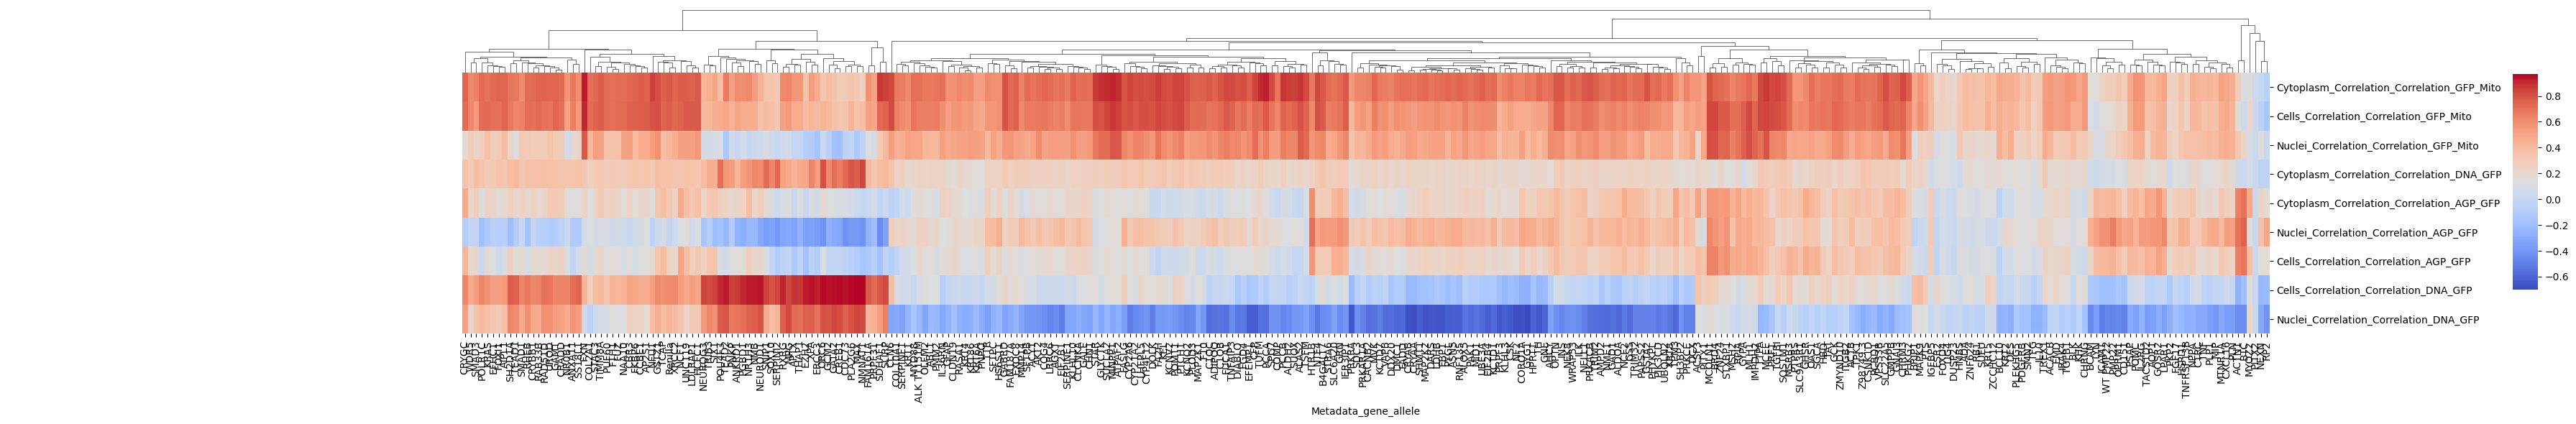

In [27]:
well_profiles_wt_gene = well_profiles_wt.group_by("Metadata_gene_allele").agg(
    pl.col(col).median().alias(col)
    for col in colocal_cols
).select(["Metadata_gene_allele"] + colocal_cols).to_pandas().set_index("Metadata_gene_allele")

## Calculate mean and standard deviation for each column
column_stats = well_profiles_wt_gene[colocal_col_dict["Correlation_Correlation"]].agg(['mean', 'std']).T
## Sort columns by the sum of mean and std in descending order
sorted_columns = column_stats.sort_values(by=["mean", "std"], ascending=False)

# sorted_columns.loc[colocal_col_dict["Correlation_Correlation"]]
# sorted_columns.loc[colocal_col_dict["Correlation_Costes"]] ## means nearly all to 1, meaningless here
# sorted_columns.loc[colocal_col_dict["Correlation_RWC"]] ## means nearly all to 1, meaningless here
# sorted_columns.loc[colocal_col_dict["Correlation_Manders"]] ## means nearly all to 1, meaningless here

# ## filter out corr columns with mean <= 1
# sorted_columns = sorted_columns[sorted_columns["mean"] > 1]
# display(sorted_columns)

g = sns.clustermap(well_profiles_wt_gene[sorted_columns.index].T, figsize=(35, 6), cmap="coolwarm", 
xticklabels=1, cbar_pos=(1., .32, .01, .5), 
row_cluster=False, col_cluster=True) ## , "viridis", z_score=0, standard_scale=0, 
rot_xticks = plt.setp(g.ax_heatmap.get_xticklabels(), rotation=90, ha="center")

## Well Profiles Visualization

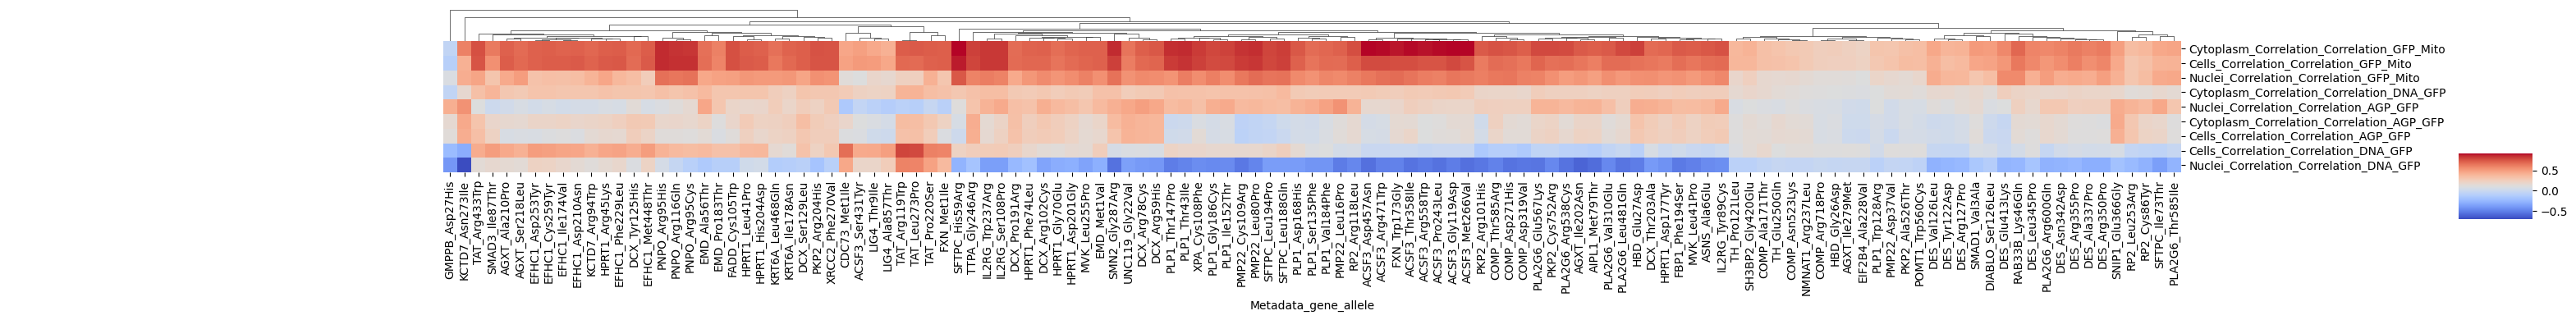

In [28]:
well_profiles_var = well_profiles.filter(
    pl.col("Metadata_gene_allele").str.contains("_")
).sort(
    pl.col(["Metadata_gene_allele","Metadata_Plate"])
)

well_profiles_var_allele = well_profiles_var.group_by(["Metadata_gene_allele"]).agg(
    pl.col(col).median().alias(col)
        for col in colocal_cols
).unique().select(["Metadata_gene_allele"] + colocal_cols).to_pandas().set_index("Metadata_gene_allele")

# Calculate mean and standard deviation for each column
column_stats = well_profiles_var_allele[colocal_col_dict["Correlation_Correlation"]].agg(['mean', 'std']).T

# Sort columns by the sum of mean and std in descending order
sorted_columns = column_stats.sort_values(by=["mean", "std"], ascending=False)

# display(well_profiles_var_allele.loc[sig_misloc_alleles, sorted_columns.index])

# sns.set(font_scale=.8)
sns.clustermap(well_profiles_var_allele.loc[sig_misloc_alleles, sorted_columns.index].T, # standard_scale=0, 
yticklabels=1, xticklabels=1, cbar_pos=(1., .32, .03, .2), figsize=(30, 4), 
cmap="coolwarm", row_cluster=False, col_cluster=True) ## , "viridis", z_score=0, 

# gfp_cols = [col for col in well_profiles_merge_plate.columns if "GFP" in col]
# well_profiles_merge_plate = well_profiles_merge_plate.select(
#     [col for col in gfp_cols if well_profiles_merge_plate[col].std() > 2] + ["Metadata_gene_allele"]
# )

In [34]:
# display(well_profiles_var_allele[sorted_columns.index])
# display(well_profiles_wt_gene[sorted_columns.index])

# well_profiles_var_allele_regroup = well_profiles_var_allele.reset_index()
# well_profiles_var_allele_regroup["Gene"] = well_profiles_var_allele_regroup["Metadata_gene_allele"].apply(lambda x: x.split("_")[0])

# misloc_scores = pd.DataFrame()
# for gene, group in well_profiles_var_allele_regroup.groupby("Gene"):
#     # print(gene)
#     # display(group)
#     group = group.set_index("Metadata_gene_allele")
#     group = group - well_profiles_wt_gene.loc[gene]
#     misloc_scores = pd.concat([misloc_scores, group], axis=0)

# # misloc_scores.columns = [col+"_var-wt" for col in misloc_scores.columns]
# misloc_scores

# sns.clustermap(misloc_scores.loc[sig_misloc_alleles,sorted_columns.index].T, xticklabels=1, cbar_pos=(1., .32, .03, .2),
# figsize=(30, 4), cmap="coolwarm", row_cluster=True, col_cluster=False) ## , "viridis", z_score=0, standard_scale=0, 

In [35]:
# import umap

# # Perform UMAP
# umap_model = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)
# umap_result = umap_model.fit_transform(misloc_scores)

# # Plot UMAP
# fig, ax = plt.subplots(1, 1, figsize=(12, 10))
# sns.scatterplot(x=umap_result[:, 0], y=umap_result[:, 1], hue=variant_type, palette="Set2", s=60, ax=ax)
# texts = []
# for i, label in enumerate(group2_labels):
#     if label in misloc_binary.filter(pl.col("mislocalized_both_batches"))["allele_0"]:
#         texts.append(ax.text(umap_result[i, 0], umap_result[i, 1], label, 
#                      fontsize=6, fontweight='bold', color='black'))
# adjust_text(texts, expand_points=(2, 2), arrowprops=dict(arrowstyle='-', color='red', lw=0.5), ax=ax) ## 
# ax.set_title("UMAP Plot")
# ax.set_xlabel("UMAP1")
# ax.set_ylabel("UMAP2")
# ax.legend(title="Variant_Type")
# plt.tight_layout()
# plt.show()

In [76]:
misloc_scores.loc[sig_misloc_alleles,sorted_columns.index]

,Nuclei_Correlation_K_GFP_Mito,Cytoplasm_Correlation_K_DNA_GFP,Cells_Correlation_K_GFP_Mito,Cytoplasm_Correlation_K_GFP_Mito,Cells_Correlation_K_DNA_GFP,Cells_Correlation_K_AGP_GFP,Cytoplasm_Correlation_K_AGP_GFP,Nuclei_Correlation_K_AGP_GFP,Nuclei_Correlation_K_DNA_GFP,Nuclei_Correlation_K_GFP_DNA,Nuclei_Correlation_K_GFP_AGP,Cytoplasm_Correlation_K_GFP_AGP,Cells_Correlation_K_GFP_AGP,Cells_Correlation_K_GFP_DNA
Metadata_gene_allele,,,,,,,,,,,,,,
PLP1_Gly186Cys,-2.603369,-0.267989,-0.993405,-0.870591,-0.713439,0.397661,0.375718,0.649498,0.215171,-0.243002,-0.427012,-0.198121,-0.173417,0.168323
PKP2_Ala526Thr,21.684850,-0.614493,23.410274,21.744666,-0.390888,-0.511045,-0.533015,-0.357423,-0.264203,3.962531,2.120959,3.242226,3.115057,4.087866
SFTPC_Leu188Gln,-0.898722,3.782019,-0.546851,-0.459940,1.277115,1.384773,1.411451,1.862281,1.903480,-0.072951,-0.062269,-0.041829,-0.036412,-0.014665
HPRT1_Arg45Lys,4.749394,-4.193965,7.412851,7.720094,-0.508617,-1.515838,-1.630521,-0.888832,-0.222531,1.045044,0.968803,1.239345,1.193544,0.941661
UNC119_Gly22Val,-5.772640,2.716577,-5.494055,-5.632875,1.164951,1.069590,1.099519,0.753174,0.377025,-0.451327,-0.393536,-0.553485,-0.531832,-0.585126
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
IL2RG_Trp237Arg,-3.542428,0.066082,-1.545033,-0.876869,0.009189,0.016480,0.010203,0.106109,0.031153,-0.264016,-0.519072,-0.102512,-0.106912,-0.055660
CDC73_Met1Ile,17.494746,-0.014794,14.227542,3.161938,-0.403108,-0.275752,-0.023666,-0.590462,-0.501187,2.733680,1.916204,0.309334,2.009418,1.971925
SMAD1_Val3Ala,15.514438,-0.804017,13.124090,11.979647,-0.486580,-0.324662,-0.294132,-0.493292,-0.499514,2.214733,1.670270,1.658176,1.657110,0.900009


In [53]:
# well_profiles_merge_plate = well_profiles_merge_plate.select(
#     [col for col in well_profiles_merge_plate.columns if not col.startswith("Metadata_")] + ["Metadata_gene_allele"]
# ).to_pandas().set_index("Metadata_gene_allele").loc[misloc_binary.filter(pl.col("mislocalized_both_batches"))["allele_0"],:]

# # from sklearn.preprocessing import StandardScaler
# # scaler = StandardScaler()
# # well_profiles_scaled = pd.DataFrame(scaler.fit_transform(well_profiles_merge_plate), columns=well_profiles_merge_plate.columns, index=well_profiles_merge_plate.index)
# # display(well_profiles_scaled)

# sns.clustermap(well_profiles_scaled, figsize=(20, 40), standard_scale=0, cmap="coolwarm", row_cluster=True, col_cluster=True) ## , "viridis"
# plt.show()